# Task 3 — Group Relative Policy Optimization (GRPO)

A **thin driver** around the Task 3 scripts (same pattern as Tasks 1–2): every experiment is a plain command in the
README; the notebook launches them, shows live training curves from the per-update logs and draws the report figures
from `results/task3_grpo/`. Finished steps are skipped (`FORCE = True` redoes them); the stop button kills the script.

| Step | What it runs | Rough time (RTX 5060 laptop, estimate) |
|---|---|---|
| 0 | objective unit tests (incl. per-group advantages) | seconds |
| 1 | standard GRPO continuation: 20 updates × 1 prompt × K=4 from the supplied midpoint | 15–25 min |
| 2 | held-out evaluation: midpoint and standard run (same protocol as PPO) | ~4–6 min each |
| 3 | group-size study K ∈ {2,4,8} on the supplied cache (no GPU) | seconds |
| 4 | normalisation study: canonical GRPO vs Dr. GRPO, 8-update forks with per-completion gradient norms + evaluation | ~25–35 min |
| 5–6 | tables, report figures (`report/figures/`), qualitative candidates | seconds |

In [1]:
# --- setup ---------------------------------------------------------------------------------------
import os, sys, json
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "configs").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import torch
from IPython.display import display, Markdown
from common.data import load_yaml, repo_path
from common.live import run_live
from task3_grpo import plots

CONFIG = os.environ.get("PA2_GRPO_CONFIG", "configs/grpo.yaml")
FORCE = False
cfg = load_yaml(CONFIG)
RES = repo_path(cfg["results_dir"])
MIDPOINT = cfg["paths"]["grpo_midpoint_policy"]

def done(path):
    return (not FORCE) and repo_path(path).exists()

print("repo root :", ROOT)
print("python    :", sys.executable)
if ".venv" not in sys.executable:
    print("WARNING: this kernel is not the repo's .venv Python - select the .venv kernel before running.")
print("torch     :", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")
print("config    :", CONFIG, "| updates", cfg["updates"], "| K", cfg["num_generations"], "| eps", cfg["clip_epsilon"],
      "| beta_KL", cfg["kl_beta"], "| cap", cfg["max_completion_length"], "| mask truncated", cfg["mask_truncated_completions"])
pd.set_option("display.max_colwidth", 120)

d:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


repo root : D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining
python    : d:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\.venv\Scripts\python.exe
torch     : 2.11.0+cu128 | CUDA: True | NVIDIA GeForce RTX 5060 Laptop GPU
config    : configs/grpo.yaml | updates 20 | K 4 | eps 0.2 | beta_KL 0.1 | cap 512 | mask truncated True


## Step 0 — objective validation

In [2]:
run_live("scripts.test_objectives", title="Objective unit tests", refresh_s=1)

Objective unit tests
FINISHED OK  |  elapsed 0m01s  |  full log: D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\notebook_logs\scripts_test_objectives.log

PASS  test_dpo_at_initialisation_is_log2
PASS  test_dpo_matches_manual_formula
PASS  test_dpo_gradient_direction
PASS  test_ppo_clip_positive_advantage
PASS  test_ppo_clip_negative_advantage
PASS  test_ppo_inside_trust_region_is_unclipped
PASS  test_ppo_mask_ignores_padding
PASS  test_gae_matches_brute_force
PASS  test_shaped_rewards_kl_and_terminal
PASS  test_gae_terminal_reward
PASS  test_grpo_advantages_are_per_group
PASS  test_grpo_advantages_invariant_to_other_groups
PASS  test_grpo_loss_normalisations
13/13 passed


## Step 1 — standard GRPO continuation (20 updates)

From the supplied midpoint adapter. Each update samples K = 4 completions for one prompt (cap 512), scores them with the
learned reward model, computes **per-group** relative advantages, masks completions that hit the cap without EOS out of
the loss (they still count in the group mean/std), and takes one clipped-surrogate step with the k3 KL penalty
(policy_epochs = 1, so the ratio is exactly 1 and clipping is inactive by construction). Logged per update: reward,
within-group reward std, uninformative-group fraction, KL, policy loss, gradient norm, entropy, length, truncation.

Standard GRPO continuation (20 updates)
FINISHED OK  |  elapsed 4m52s  |  full log: D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\notebook_logs\task3_grpo_continue_train.log



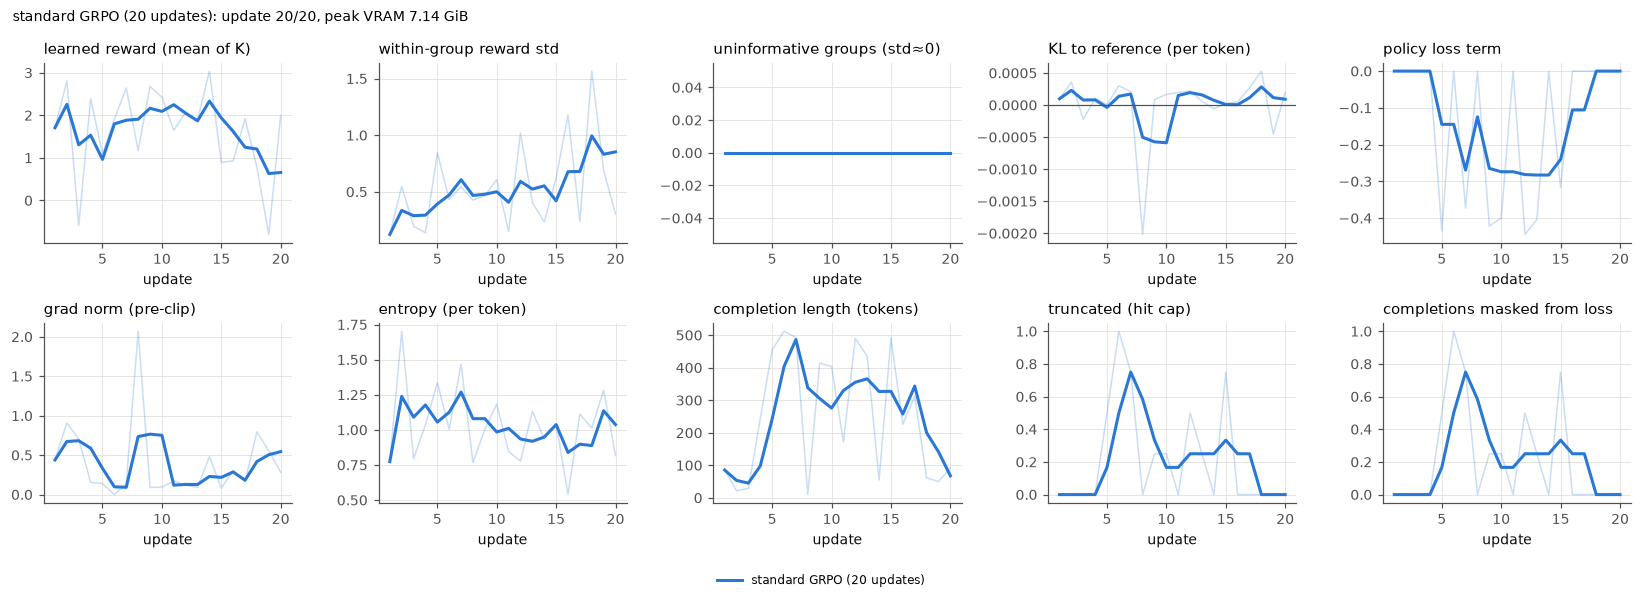

[standard] update 4/20 reward=+2.389 grp_std=0.138 zero_std=0.00 kl_tok=+0.0001 loss=+0.0000 |g|=0.156 len=244 trunc=0.00 t=23s eta=1.5min
[standard] update 5/20 reward=+1.103 grp_std=0.845 zero_std=0.00 kl_tok=+0.0000 loss=-0.4344 |g|=0.140 len=455 trunc=0.50 t=47s eta=2.4min
[standard] update 6/20 reward=+1.908 grp_std=0.433 zero_std=0.00 kl_tok=+0.0003 loss=+0.0000 |g|=0.000 len=512 trunc=1.00 t=70s eta=2.7min
[standard] update 7/20 reward=+2.642 grp_std=0.544 zero_std=0.00 kl_tok=+0.0002 loss=-0.3729 |g|=0.137 len=493 trunc=0.75 t=93s eta=2.9min
[standard] update 8/20 reward=+1.175 grp_std=0.427 zero_std=0.00 kl_tok=-0.0020 loss=+0.0000 |g|=2.070 len=10 trunc=0.00 t=94s eta=2.4min
[standard] update 9/20 reward=+2.679 grp_std=0.466 zero_std=0.00 kl_tok=+0.0001 loss=-0.4211 |g|=0.090 len=414 trunc=0.25 t=117s eta=2.4min
[standard] update 10/20 reward=+2.426 grp_std=0.609 zero_std=0.00 kl_tok=+0.0002 loss=-0.4001 |g|=0.095 len=404 trunc=0.25 t=139s eta=2.3min
[standard] update 11/20 r

**Standard continuation:** wall-clock **4.5 min**, peak VRAM **7.141 GiB**, 20218 generated tokens

In [3]:
if done("outputs/task3_grpo/standard/adapter_model.safetensors"):
    print("Standard GRPO adapter exists - skipping (set FORCE = True to retrain).")
    display(plots.train_curves(cfg, ["standard"]))
else:
    run_live("task3_grpo.continue_train", "--config", CONFIG, "--run-name", "standard",
             title="Standard GRPO continuation (20 updates)", plot_fn=lambda: plots.train_curves(cfg, ["standard"]))
summary = plots._json(RES / "standard" / "train_summary.json")
display(Markdown(f"**Standard continuation:** wall-clock **{summary['wall_clock_s'] / 60:.1f} min**, "
                 f"peak VRAM **{summary['peak_vram_gib']} GiB**, {summary['generated_tokens']} generated tokens"))

## Step 2 — held-out evaluation: supplied midpoint vs standard run
Same protocol as Task 2 (`common/rl_eval.py`): first 96 held-out prompts within the prompt cap, one seeded sample each,
cap 768 tokens.

In [4]:
for name, adapter in [("midpoint", MIDPOINT), ("standard", "outputs/task3_grpo/standard")]:
    if done(f"{cfg['results_dir']}/{name}/eval_heldout.json"):
        print(f"{name}: evaluation exists - skipping.")
    else:
        run_live("task3_grpo.evaluate", "--config", CONFIG, "--adapter", adapter, "--name", name,
                 title=f"Held-out evaluation: {name}", refresh_s=10)

Held-out evaluation: standard
FINISHED OK  |  elapsed 3m36s  |  full log: D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\notebook_logs\task3_grpo_evaluate.log

W1010 15:38:14.847000 26796 .venv\Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
[eval:standard] held-out evaluation: 96 prompts (15 skipped as longer than 256 tokens), cap 768 tokens, adapter=outputs/task3_grpo/standard
[eval:standard] generation batch 1/3 (11s elapsed)
[eval:standard] generation batch 2/3 (64s elapsed)
[eval:standard] generation batch 3/3 (119s elapsed)
[eval:standard] scoring 96 responses with the reward model
[eval:standard] reward=1.870 (with EOS penalty 1.870) kl_tok=0.0001 entropy=0.945 len=296.7 trunc=0.09 (3.3 min)


## Step 3 — group-size study (equal generation budget, no training)
Each prompt's 8 cached completions are split at random into 8/K disjoint groups of K, so K = 2, 4, 8 all use the same 192
generations; 500 seeded random partitions are averaged. Prompt difficulty = tercile of the prompt's mean reward over its
8 cached completions.

In [5]:
run_live("task3_grpo.analyze_group_size", "--config", CONFIG, title="Group-size study", refresh_s=2)
gs = pd.read_csv(RES / "group_size_study.csv")
display(gs.set_index(["bin", "K"]).round(4))

Group-size study
FINISHED OK  |  elapsed 0m03s  |  full log: D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\notebook_logs\task3_grpo_analyze_group_size.log

Cached prompts: 24 | total generations: 192
Group sizes to analyze: [2, 4, 8]
wrote D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\task3_grpo\group_size_study.csv
K=2: informative 0.947 (tol0.1 0.743) mean std 0.386 centred^2 0.322 adv partition var 0.535
K=4: informative 0.958 (tol0.1 0.923) mean std 0.549 centred^2 0.480 adv partition var 0.193
K=8: informative 0.958 (tol0.1 0.958) mean std 0.619 centred^2 0.560 adv partition var 0.000


groups_per_partition  informative_rate  \
bin                     K                                           
all                     2                    96            0.9475   
                        4                    48            0.9583   
                        8                    24            0.9583   
hard (low mean reward)  2                    32            0.8712   
                        4                    16            0.8750   
                        8                     8            0.8750   
medium                  2                    32            0.9812   
                        4                    16            1.0000   
                        8                     8            1.0000   
easy (high mean reward) 2                    32            0.9899   
                        4                    16            1.0000   
                        8                     8            1.0000   

                           mean_group_reward_std  mean_centred_reward_sq  \
bin                     K                                                  
all                     2                 0.3864                  0.3225   
                        4                 0.5494                  0.4801   
                        8                 0.6191                  0.5599   
hard (low mean reward)  2                 0.4842                  0.5141   
                        4                 0.6825                  0.7593   
                        8                 0.7634                  0.8869   
medium                  2                 0.3678                  0.2563   
                        4                 0.5238                  0.3817   
                        8                 0.5990                  0.4469   
easy (high mean reward) 2                 0.3072                  0.1969   
                        4                 0.4419                  0.2993   
                        8                 0.4948                  0.3459   

                           advantage_partition_variance  \
bin                     K                                 
all                     2                        0.5354   
                        4                        0.1926   
                        8                        0.0000   
hard (low mean reward)  2                        0.4943   
                        4                        0.1650   
                        8                        0.0000   
medium                  2                        0.5532   
                        4                        0.2145   
                        8                        0.0000   
easy (high mean reward) 2                        0.5587   
                        4                        0.1982   
                        8                        0.0000   

                           informative_rate_tol0.1  informative_rate_tol0.25  
bin                     K                                                     
all                     2                   0.7430                    0.4972  
                        4                   0.9230                    0.7687  
                        8                   0.9583                    0.8750  
hard (low mean reward)  2                   0.7549                    0.5669  
                        4                   0.8732                    0.8322  
                        8                   0.8750                    0.8750  
medium                  2                   0.7690                    0.5162  
                        4                   0.9524                    0.8178  
                        8                   1.0000                    1.0000  
easy (high mean reward) 2                   0.7050                    0.4084  
                        4                   0.9434                    0.6561  
                        8                   1.0000                    0.7500

## Step 4 — sequence-normalisation study: canonical GRPO (1/T_k) vs Dr. GRPO (1/L)
Two matched 8-update forks from the identical midpoint; only the per-sequence normaliser differs. Both record each
completion's own gradient norm, so the allocation of gradient magnitude across short and long completions is measured
directly (a length-conditioned gradient statistic). Both forks are evaluated with the common protocol.

Normalisation study
FINISHED OK  |  elapsed 11m13s  |  full log: D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\notebook_logs\task3_grpo_compare_normalization.log



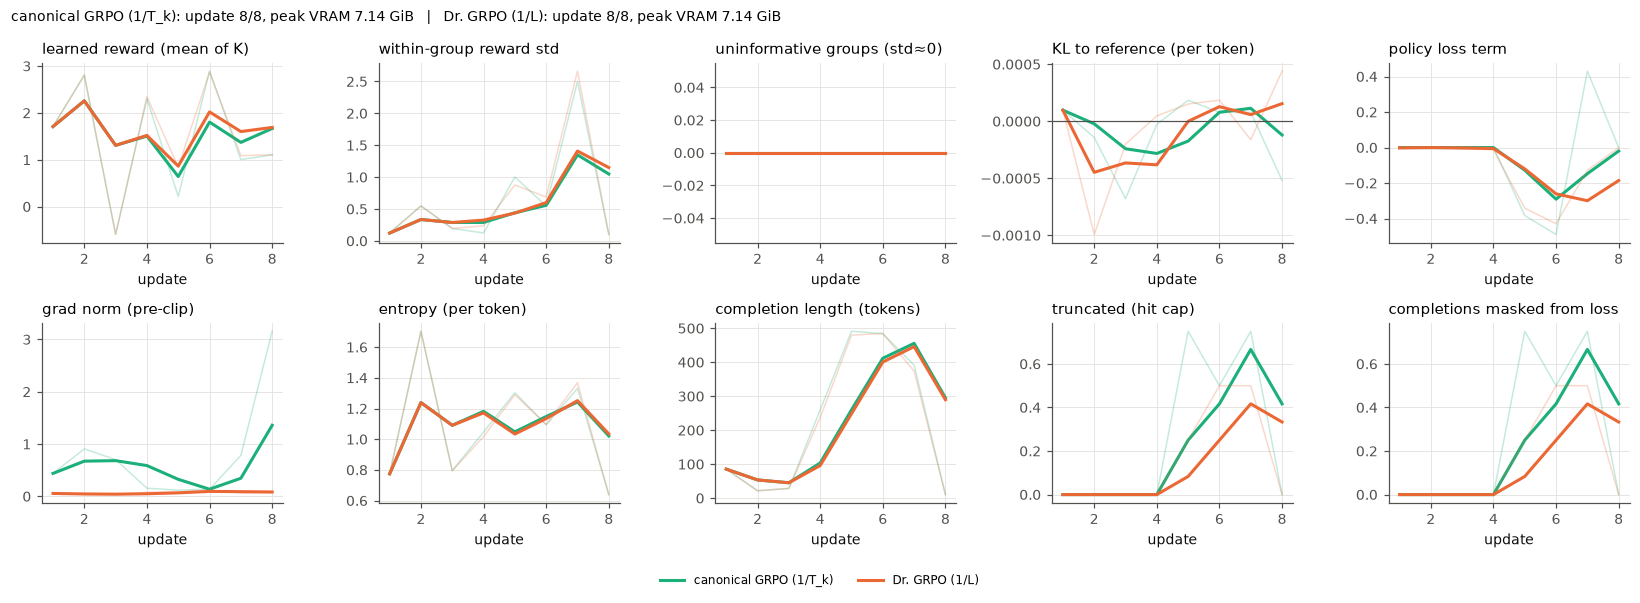

[norm_dr_grpo] update 2/8 reward=+2.806 grp_std=0.549 zero_std=0.00 kl_tok=-0.0010 loss=+0.0020 |g|=0.036 len=22 trunc=0.00 t=11s eta=0.5min
[norm_dr_grpo] update 3/8 reward=-0.593 grp_std=0.195 zero_std=0.00 kl_tok=-0.0002 loss=-0.0068 |g|=0.034 len=29 trunc=0.00 t=13s eta=0.4min
[norm_dr_grpo] update 4/8 reward=+2.346 grp_std=0.237 zero_std=0.00 kl_tok=+0.0000 loss=-0.0122 |g|=0.079 len=238 trunc=0.00 t=29s eta=0.5min
[norm_dr_grpo] update 5/8 reward=+0.842 grp_std=0.878 zero_std=0.00 kl_tok=+0.0002 loss=-0.3412 |g|=0.087 len=480 trunc=0.25 t=58s eta=0.6min
[norm_dr_grpo] update 6/8 reward=+2.875 grp_std=0.688 zero_std=0.00 kl_tok=+0.0002 loss=-0.4287 |g|=0.117 len=485 trunc=0.50 t=86s eta=0.5min
[norm_dr_grpo] update 7/8 reward=+1.089 grp_std=2.663 zero_std=0.00 kl_tok=-0.0002 loss=-0.1277 |g|=0.065 len=374 trunc=0.50 t=114s eta=0.3min
[norm_dr_grpo] update 8/8 reward=+1.105 grp_std=0.102 zero_std=0.00 kl_tok=+0.0004 loss=-0.0006 |g|=0.069 len=10 trunc=0.00 t=116s eta=0.0min
[norm_d

In [6]:
run_live("task3_grpo.compare_normalization", "--config", CONFIG, title="Normalisation study",
         plot_fn=lambda: plots.train_curves(cfg, plots.NORM_FORKS))

## Step 5 — results

In [12]:
import subprocess
subprocess.run([sys.executable, "-m", "task3_grpo.compare_normalization", "--config", CONFIG, "--summary-only"],
               cwd=ROOT, check=False, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
rows = []
for name in ["midpoint", "standard", *plots.NORM_FORKS]:
    ev = plots._json(RES / name / "eval_heldout.json")
    if ev:
        rows.append({"condition": name, "reward": ev["reward_raw_mean"], "reward_ci95": ev["reward_raw_ci95"],
                     "kl_token": ev["kl_token_mean"], "kl_seq": ev["kl_seq_mean"], "entropy": ev["entropy_mean"],
                     "len_mean": ev["response_tokens"]["mean"], "len_std": ev["response_tokens"]["std"],
                     "truncation": ev["truncation_rate"]})
display(Markdown("**Held-out evaluation (common protocol)**"))
display(pd.DataFrame(rows).set_index("condition").round(4))
norm = plots._json(RES / "summary_normalization.json")
if norm:
    display(Markdown("**Normalisation forks**"))
    display(pd.DataFrame(norm["forks"]).set_index("fork").T)
    display(Markdown(f"**Length-conditioned statistics** (length bins split at the pooled median, "
                     f"{norm['length_conditioned'].get('median_length_cut')} tokens)"))
    display(pd.DataFrame(norm["length_bins"]).round(5))
    display(pd.DataFrame(norm["length_conditioned"].get("slopes", {})).round(4))

**Held-out evaluation (common protocol)**

,reward,reward_ci95,kl_token,kl_seq,entropy,len_mean,len_std,truncation
condition,,,,,,,,
midpoint,1.7696,"[1.4809171676635742, 2.022275193532308]",0.0001,0.0224,0.9470,299.8958,264.6031,0.1042
standard,1.8696,"[1.6161856651306152, 2.0975276311238606]",0.0001,0.0189,0.9450,296.6562,258.2345,0.0938
norm_grpo,1.7855,"[1.4979607899983725, 2.0425503412882486]",0.0000,0.0099,0.9416,301.9688,265.8382,0.1042
norm_dr_grpo,1.7377,"[1.4573510424544414, 1.984249132250746]",0.0001,0.0164,0.9459,300.8542,264.0502,0.1042


**Normalisation forks**

fork,norm_grpo,norm_dr_grpo
loss_type,grpo,dr_grpo
train_generated_tokens,7094,6889
train_reward_mean,1.430222,1.522331
train_len_first,85.5,85.5
train_len_last,10.5,10.5
train_len_mean,221.6875,215.28125
train_grad_norm_mean,0.799836,0.067891
heldout_reward,1.785494,1.737739
heldout_reward_ci95,"[1.4979607899983725, 2.0425503412882486]","[1.4573510424544414, 1.984249132250746]"
heldout_kl_token,0.000033,0.000055


**Length-conditioned statistics** (length bins split at the pooled median, 38.0 tokens)

,fork,advantage_sign,length_bin,n,mean_length,mean_abs_advantage,mean_per_token_weight,mean_seq_grad_norm
0,norm_grpo,A>0,short (<= 38 tok),5,20.00000,1.05323,0.01611,0.70623
1,norm_grpo,A>0,long (> 38 tok),7,287.42857,1.02743,0.00154,0.13835
2,norm_grpo,A<0,short (<= 38 tok),8,21.75000,0.87358,0.01273,0.64588
3,norm_grpo,A<0,long (> 38 tok),4,178.00000,0.92604,0.00205,0.13924
4,norm_dr_grpo,A>0,short (<= 38 tok),5,20.00000,1.05323,0.00051,0.02245
5,norm_dr_grpo,A>0,long (> 38 tok),8,337.00000,0.97000,0.00047,0.05487
6,norm_dr_grpo,A<0,short (<= 38 tok),8,21.75000,0.87364,0.00043,0.02042
7,norm_dr_grpo,A<0,long (> 38 tok),6,226.50000,0.58715,0.00029,0.02022


,norm_grpo,norm_dr_grpo
loglog_slope_gradnorm_vs_length,-0.6426,0.1907
corr_length_gradnorm,-0.4895,0.4488
n,24.0000,27.0000
corr_length_advantage,0.3096,0.3084


saved D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\report\figures\task3_standard_training.png


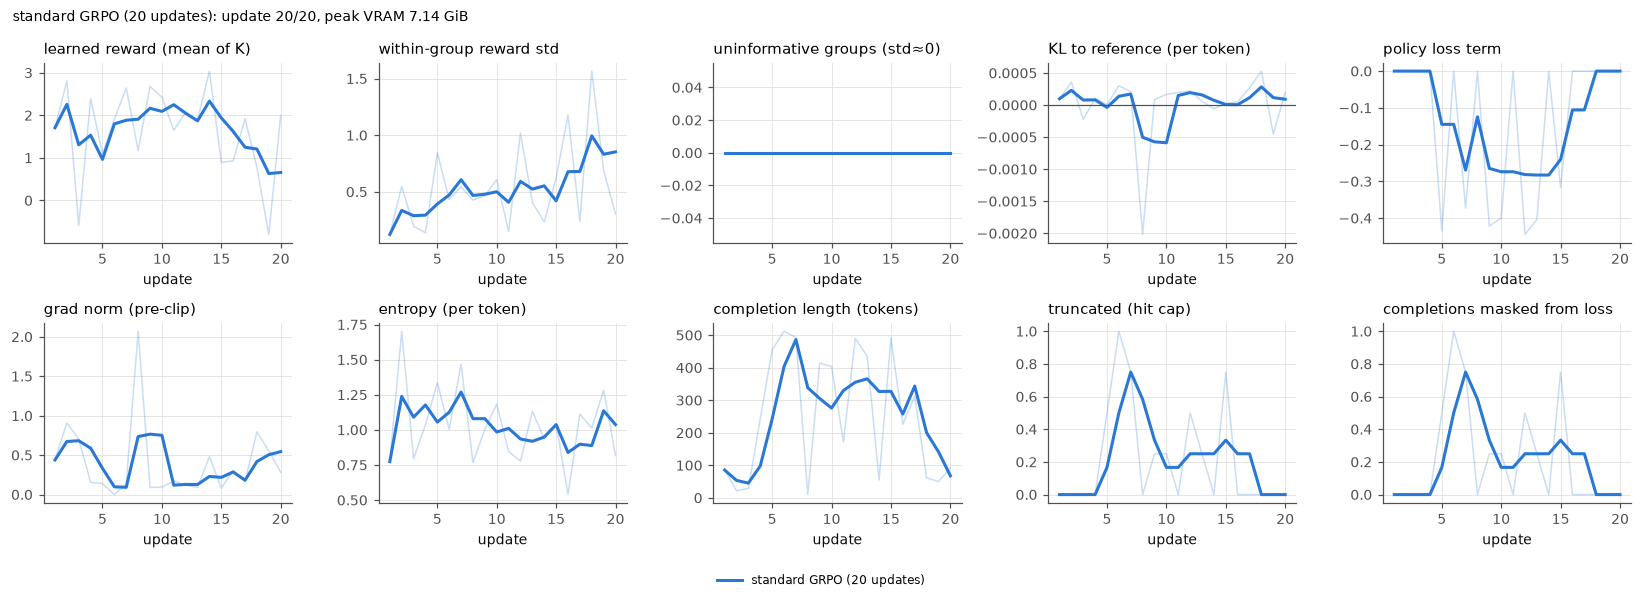

saved D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\report\figures\task3_group_size_study.png


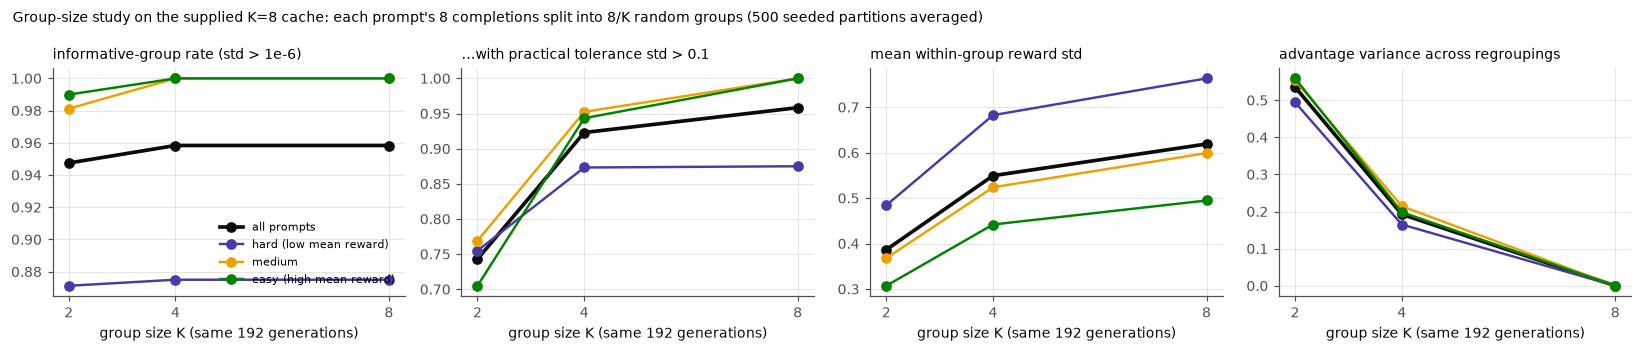

saved D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\report\figures\task3_normalization_study.png


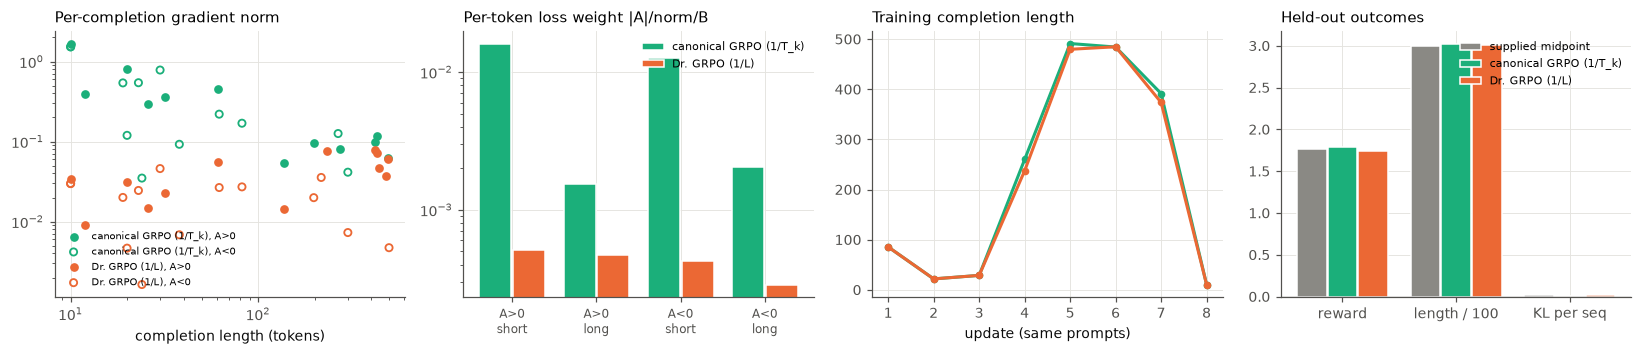

saved D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\report\figures\task3_fork_training.png


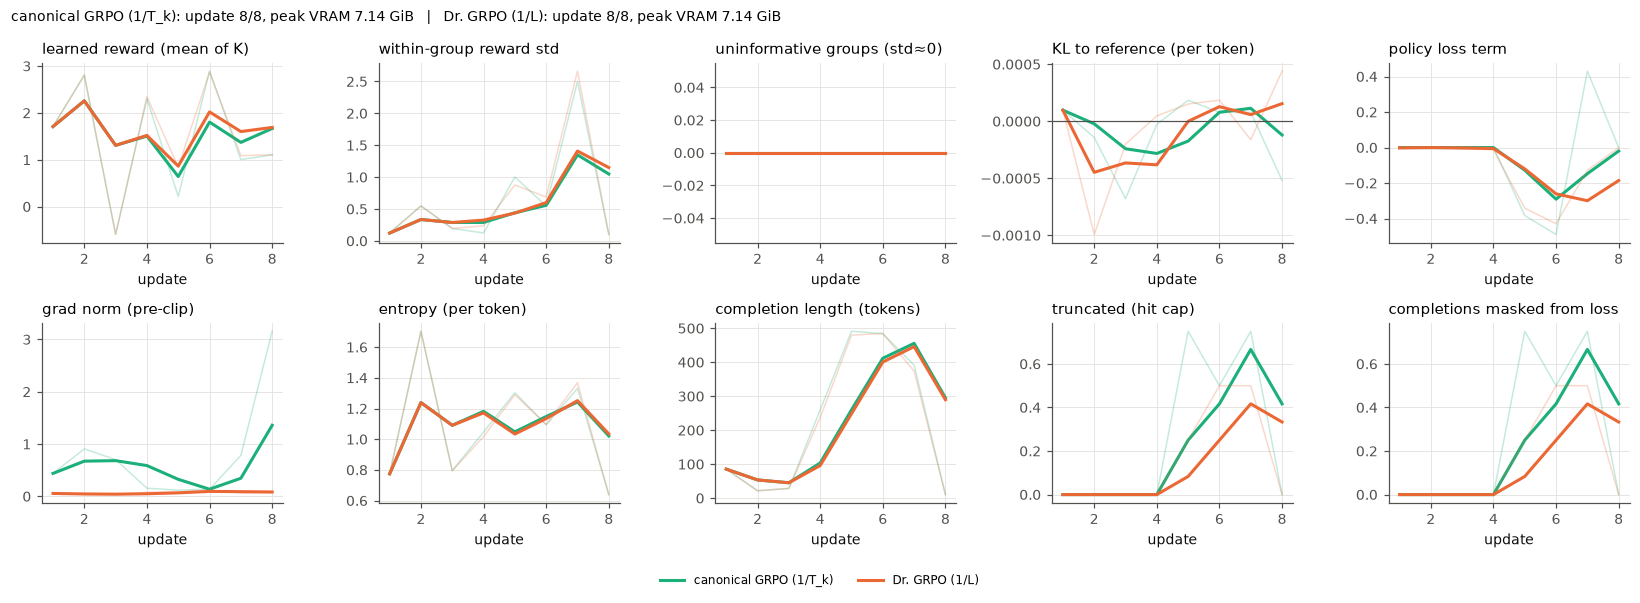

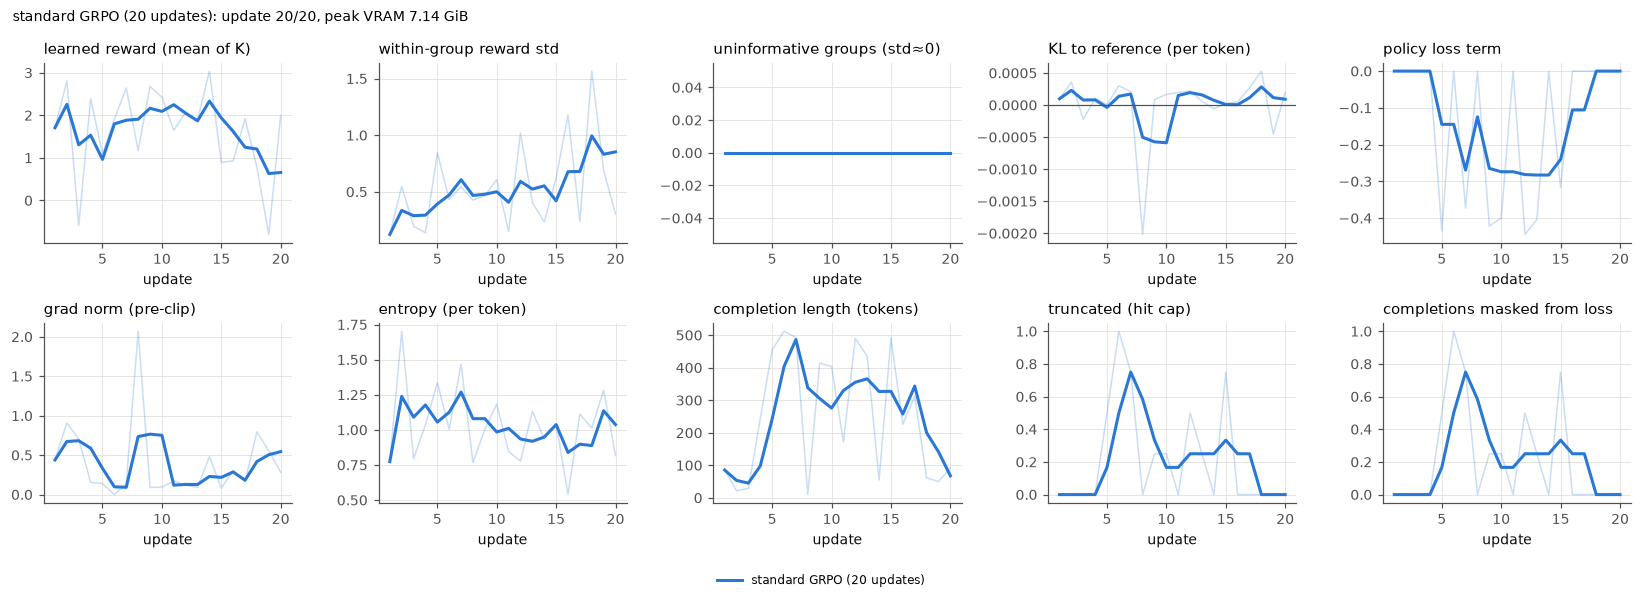

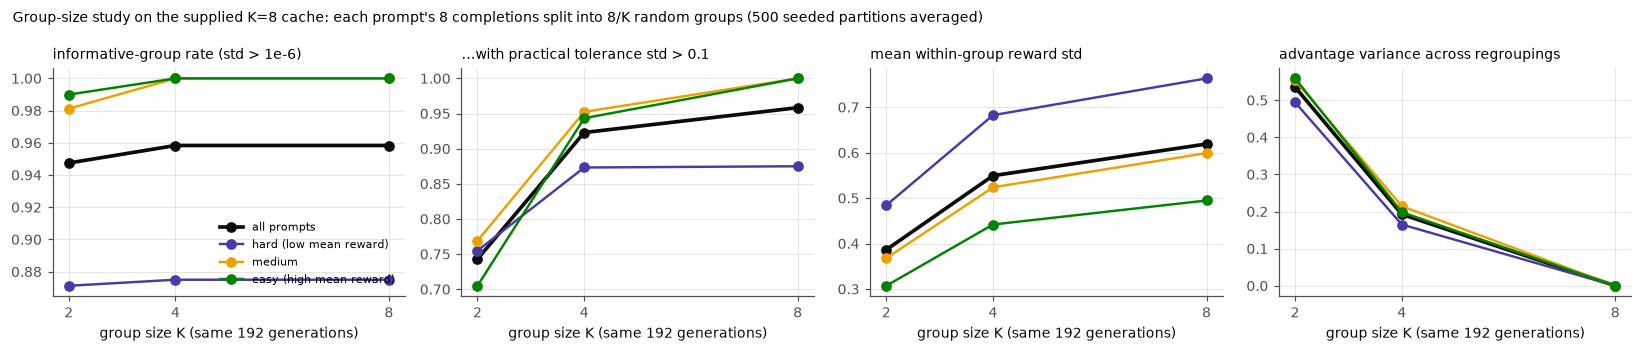

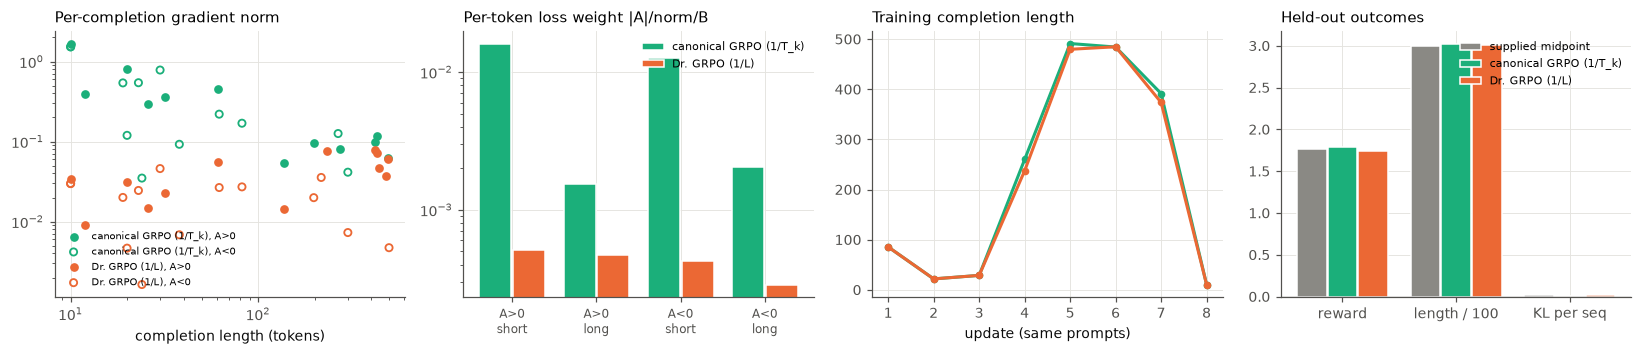

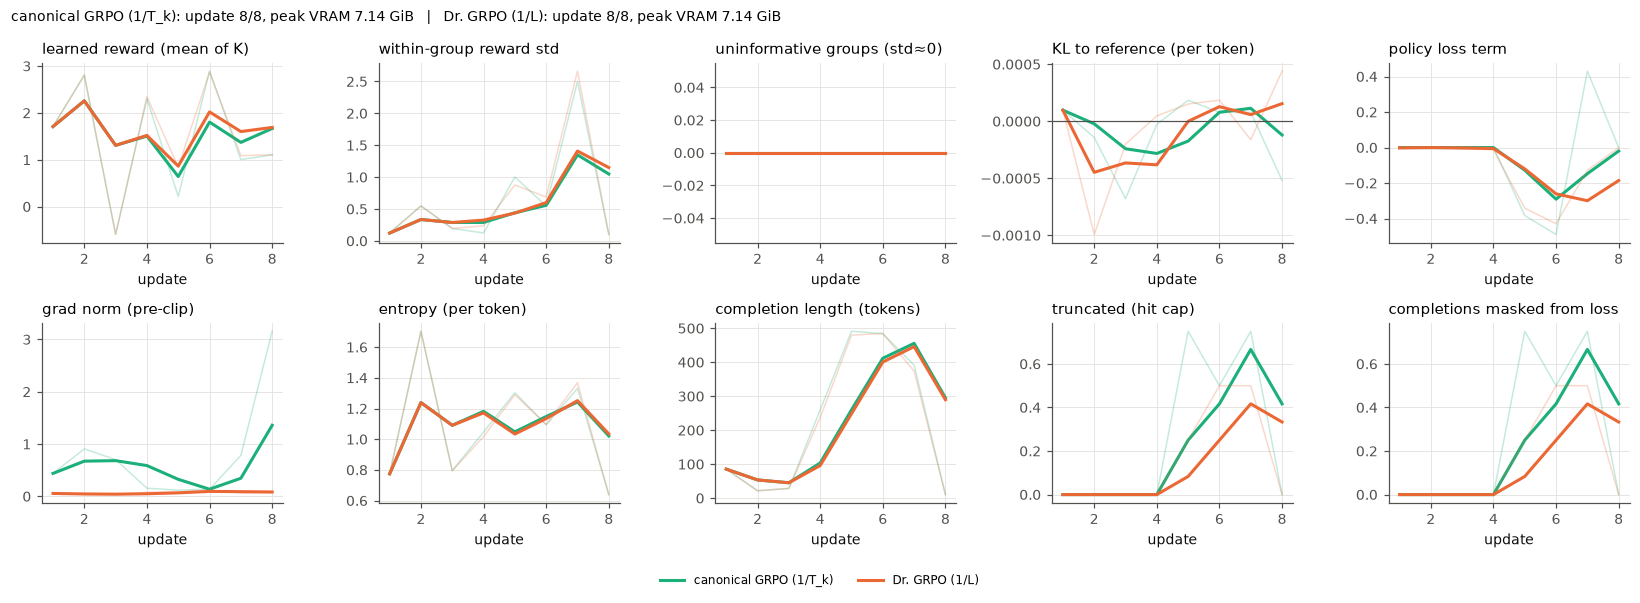

In [8]:
figs = {
    "task3_standard_training": plots.train_curves(cfg, ["standard"]),
    "task3_group_size_study": plots.group_size_study(cfg),
    "task3_normalization_study": plots.normalization_study(cfg),
    "task3_fork_training": plots.train_curves(cfg, plots.NORM_FORKS),
}
for name, fig in figs.items():
    plots.save(fig, name)
    if fig is not None:
        display(fig)

## Step 6 — qualitative candidates
Candidates only — read them and judge quality yourself before quoting anything in the report.

In [9]:
display(Markdown("**Largest held-out reward gains: standard GRPO vs midpoint**"))
display(plots.reward_change_candidates(cfg, "standard", "midpoint", k=6))
display(Markdown("**Uninformative / least informative training groups (standard run)**"))
display(plots.uninformative_groups(cfg, "standard"))

**Largest held-out reward gains: standard GRPO vs midpoint**

,prompt_id,reward_change,standard_reward,midpoint_reward,standard_tokens,midpoint_tokens,standard_truncated,prompt,standard_response,midpoint_response
25,3b9a463645ced45abcdd251adcb76f4f8e7011df96b46e18af1b670410e60230,2.880859,1.143555,-1.737305,241,59,False,"Create a detailed storyboard illustrating the main events of the science-fiction movie ""Avatar"", while also includin...","As an AI language model, I can certainly provide you with a detailed storyline for your request, but unfortunately, ...","As an AI language model, I can certainly help you create a detailed storyboard for your science fiction movie ""Avata..."
93,89329ac82483a5d974f7b853e22923e5405ffc6d81bab3c84a8beab932d48a71,1.865723,2.621094,0.755371,176,89,False,"In this task, you will be presented with a question having multiple possible answers in Dutch language. And you shou...",The correct answer is: A gevonden Explanation: This sentence describes someone who borrowed a metal detector to try ...,The correct answer is A: gevonden. Explanation: This sentence describes someone who borrowed a metal detector to try...
21,15837ad2725266a35255f91d2e023ea644ede5cb9d7ec9270ab3c6dd6449a74c,1.849701,1.878906,0.029205,615,768,False,"need to use Python to maximize a window and wait for a specific text , after the text appear , i need to write some ...","To achieve your goal using Python, you can utilize several libraries such as `selenium` for interacting with web pag...","To achieve your goal using Python, you can utilize several libraries such as `selenium` for interacting with web pag..."
80,a68322e9ef99336c810c507061658df3f91069069e937f4c2e840fbcfe55ba65,1.722656,2.851562,1.128906,690,768,False,How can I use PHP to create a dynamic webpage that changes the appearance of the sun based on the time of day? For e...,"To achieve this effect in a dynamic web page with PHP and CSS, we'll need to do some server-side processing to deter...","To achieve this effect in a dynamic web page with PHP and CSS, we'll need to do some server-side processing to deter..."
68,c359f7ed5e4a168b1e27bd1c27dc9752980103a2e1b38991e5011a7ea44d214e,1.470703,3.214844,1.744141,768,768,True,"Write a 700-word opinion piece using a journalistic style of writing, discussing the ethical, environmental, and hea...","Plant-Based Diets: A Growing Trend for Ethical, Environmental, and Health Reasons As we continue to grapple with the...","Plant-Based Diets: A Growing Trend for Ethical, Environmental, and Health Reasons As we continue to grapple with the..."
11,df363c927f8727d9ebc6f7214215191c62a1ff41796c6b22f9ff37fa991f9121,1.275391,2.228516,0.953125,734,768,False,I want to parse a struct in a go source file and want to generate a avro schema from it. Please write a Go program t...,"To achieve this task, you can use the `golang.org/x/tools/imports` package for importing the necessary packages and ...","To achieve this task, you can use the `golang.org/x/tools/imports` package for importing the necessary packages and ..."


**Uninformative / least informative training groups (standard run)**

,update,prompt_id,reward_std,reward_mean,lengths,first_response
0,1,b70ebc9bc95bf8332673d0762848d1005ba550cdfeea97b46887e2c1ac794f92,0.123421,1.708740,"[62, 82, 61, 137]","Ha aparecido en películas musicales y más tarde en su vida, en papeles cómicos. Rationale: This is a correct and acc..."
3,4,184b5777cf166a9f4970d3170e88a14b9855c477b326041a5ad9387695b3934e,0.138420,2.389160,"[276, 198, 234, 267]","MTV is a global media company that produces music videos, television shows, films, and other content for audiences a..."
10,11,c1b63ef79dc5fdc242a3f83c829d516bb6aee879c75dbedd4df2256944697bc1,0.148037,1.646484,"[149, 192, 174, 172]","As an AI language model, I don't have the ability to taste food or eat French fries. However, I can understand that ..."
2,3,66d02a300fac38a49c06e0fe08f4a039cd6cf597c39d5d3cc5e1b64968f70fbd,0.195174,-0.593445,"[38, 32, 26, 19]",Of course! Please provide the statement or question that you would like reviewed and analyzed. Once I have the detai...
13,14,ea35663c4537d46ecfcbec4cccfefca34dd6553cddb80b74bb450e048dad5d26,0.233304,3.038574,"[29, 31, 101, 59]",negative Reason: The statement expresses strong dissatisfaction and disappointment towards others who disrupted an i...
16,17,c281bcba0d91ac075f15b0c8ad94afde4afa1df61a0505473b2bd6439515d25b,0.240907,1.924072,"[200, 473, 230, 350]","Dear Senator [Last Name], I am reaching out to you today because I have been contacted by a local resident who is in..."


In [10]:
for run in plots.NORM_FORKS:
    display(Markdown(f"**Shortest and longest training completions in the loss — {plots.LABELS[run]}**"))
    display(plots.extreme_completions(cfg, run, k=3))

**Shortest and longest training completions in the loss — canonical GRPO (1/T_k)**

,update,tokens,reward,advantage,per_token_weight,seq_grad_norm,response
0,8,10,1.006836,-0.968710,0.024218,1.526353,"[-5.5, -49]"
1,8,10,1.239258,1.319657,0.032991,1.678883,"[2.5, -39]"
2,8,10,1.006836,-0.968710,0.024218,1.526350,"[-5.5, -49]"
3,6,420,3.548828,1.201728,0.000715,0.098557,The excessive and compulsive use of the internet can have profound multifaceted consequences that extend beyond just...
4,5,429,1.750977,1.530759,0.000892,0.118148,"Title: ""The First Step"" INTRO (0-5 seconds) Fade-in to a shot of a young woman sitting alone on a bench at a communi..."
5,6,493,3.304688,0.755321,0.000383,0.061703,Excessive and compulsive internet use can lead to several significant consequences: 1. **Physical Health Implication...


**Shortest and longest training completions in the loss — Dr. GRPO (1/L)**

,update,tokens,reward,advantage,per_token_weight,seq_grad_norm,response
0,8,10,1.006836,-0.968710,0.000473,0.029857,"[-5.5, -49]"
1,8,10,1.239258,1.319657,0.000644,0.034155,"[2.5, -39]"
2,8,10,1.006836,-0.968710,0.000473,0.029857,"[-5.5, -49]"
3,5,479,1.315430,0.538924,0.000263,0.037430,"Title: ""The First Time"" FADE IN: EXT. COLLEGE CAMPUS - DAY We see a close-up shot of a young woman sitting on a benc..."
4,6,493,3.408203,0.776209,0.000379,0.061051,Excessive and compulsive internet use can lead to several significant consequences: 1. **Physical Health Implication...
5,5,499,0.784180,-0.066340,0.000032,0.004720,INT. COLLEGE HALLWAY - DAY We see JEN (23) walking down the hallway towards her classroom with a backpack slung over...
